In [43]:
import os
import pandas as pd
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.pipeline import make_pipeline
from imblearn.pipeline import make_pipeline as imbl_pipe
from imblearn.over_sampling import SMOTE

Load Analytical Base Table

In [ ]:
abt_data = pd.read_csv("/Users/abhisubrahmanyamkamuju/Desktop/ML_Project/analytical_base_table.csv")
abt_data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Models Training
Let's start by splitting our dataframe into separate objects:

y for the target varibale

X for the input features

In [ ]:
y_target = abt_data.Exited
X_features = abt_data.drop(['Exited'], axis=1)
print(X_features.shape, y_target.shape)

(10000, 10) (10000,)


In [ ]:
num_cols = X_features.select_dtypes(include='number').columns.tolist()
cat_cols = X_features.select_dtypes(include='object').columns.tolist()

In [ ]:
def class_count(arr):
    counter = Counter(arr)
    kv = [list(counter.keys()), list(counter.values())]
    df_counts = pd.DataFrame(np.array(kv).T, columns=['Exited', 'Count'])
    df_counts['Count'] = df_counts['Count'].astype('int64')
    df_counts['%'] = round(df_counts['Count'] / arr.shape[0] * 100, 2)
    return df_counts.sort_values('Count', ascending=False)

Create a Train Test Split

We will continue with splitting our data into separate training and test sets.

30% of observations will be set aside for the test set

the rest, 70%, will be used as the training set

In [ ]:
random_state = 10

X_train, X_test, y_train, y_test = train_test_split(X_features, y_target,
                                                    test_size=0.3,
                                                    random_state=random_state,
                                                    stratify=abt_data.Exited)

print(len(X_train), len(X_test), len(y_train), len(y_test))
X_train.info()

7000 3000 7000 3000
<class 'pandas.core.frame.DataFrame'>
Index: 7000 entries, 8061 to 4741
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      7000 non-null   int64  
 1   Geography        7000 non-null   object 
 2   Gender           7000 non-null   object 
 3   Age              7000 non-null   int64  
 4   Tenure           7000 non-null   int64  
 5   Balance          7000 non-null   float64
 6   NumOfProducts    7000 non-null   int64  
 7   HasCrCard        7000 non-null   int64  
 8   IsActiveMember   7000 non-null   int64  
 9   EstimatedSalary  7000 non-null   float64
dtypes: float64(2), int64(6), object(2)
memory usage: 601.6+ KB


Pre-processing Pipeline

Scale numerical data and encode categorical data

Construct a pre-processing pipeline from the given transformers: MinMaxScaler and OneHotEncoder Create lists of indexes from the list of column namesNeed to be numeric not string to specify columns name in column transformer

In [ ]:
num_indices = [] 

for col in num_cols:
    loc = X_features.columns.get_loc(col)
    num_indices.append(loc)
print(num_indices)  

cat_indices = []

for col in cat_cols:
    loc = X_features.columns.get_loc(col)
    cat_indices.append(loc)
print(cat_indices) 

[0, 3, 4, 5, 6, 7, 8, 9]
[1, 2]


In [ ]:
preprocessor = make_column_transformer(
    (MinMaxScaler(), num_indices),
    (OneHotEncoder(), cat_indices)
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model_pipe = imbl_pipe(preprocessor,
                       SMOTE(sampling_strategy='auto', random_state=random_state),
                       RandomForestClassifier())

In [ ]:
rf_param_grid = {
    'randomforestclassifier__n_estimators': [50, 100, 150],
    'randomforestclassifier__max_features': ['sqrt', 0.33],
    'randomforestclassifier__min_samples_leaf': [1, 5 ,10, 15],
    'randomforestclassifier__criterion': ['gini', 'entropy'],
    'randomforestclassifier__min_samples_split': [2, 3, 4]
}

In [ ]:
from sklearn.model_selection import GridSearchCV

rf_grid_search = GridSearchCV(model_pipe, rf_param_grid, verbose=3, cv=5, scoring='accuracy')

X_train = X_train.values
X_test = X_test.values
rf_grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 144 candidates, totalling 720 fits
[CV 1/5] END randomforestclassifier__criterion=gini, randomforestclassifier__max_features=sqrt, randomforestclassifier__min_samples_leaf=1, randomforestclassifier__min_samples_split=2, randomforestclassifier__n_estimators=50;, score=0.838 total time=   0.6s
[CV 2/5] END randomforestclassifier__criterion=gini, randomforestclassifier__max_features=sqrt, randomforestclassifier__min_samples_leaf=1, randomforestclassifier__min_samples_split=2, randomforestclassifier__n_estimators=50;, score=0.843 total time=   0.6s
[CV 3/5] END randomforestclassifier__criterion=gini, randomforestclassifier__max_features=sqrt, randomforestclassifier__min_samples_leaf=1, randomforestclassifier__min_samples_split=2, randomforestclassifier__n_estimators=50;, score=0.830 total time=   0.6s
[CV 4/5] END randomforestclassifier__criterion=gini, randomforestclassifier__max_features=sqrt, randomforestclassifier__min_samples_leaf=1, randomforestclassifier_

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(transformers=[('minmaxscaler',
                                                                         MinMaxScaler(),
                                                                         [0, 3,
                                                                          4, 5,
                                                                          6, 7,
                                                                          8,
                                                                          9]),
                                                                        ('onehotencoder',
                                                                         OneHotEncoder(),
                                                                         [1,
                                                                          2])])),
                                       ('smote', SMOTE(random_state=10)),
                                       ('randomforestclassifier',
                                        RandomForestClassifier())]),
             param_grid={'randomforestclassifier__criterion': ['gini',
                                                               'entropy'],
                         'randomforestclassifier__max_features': ['sqrt', 0.33],
                         'randomforestclassifier__min_samples_leaf': [1, 5, 10,
                                                                      15],
                         'randomforestclassifier__min_samples_split': [2, 3, 4],
                         'randomforestclassifier__n_estimators': [50, 100,
                                                                  150]},
             scoring='accuracy', verbose=3)

In [ ]:
print(rf_grid_search.best_params_)
print(rf_grid_search.best_score_)
print(f"Training Data Score: {rf_grid_search.score(X_train, y_train)}")
print(f"Testing Data Score: {rf_grid_search.score(X_test, y_test)}")

{'randomforestclassifier__criterion': 'entropy', 'randomforestclassifier__max_features': 0.33, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__min_samples_split': 2, 'randomforestclassifier__n_estimators': 100}
0.8435714285714285
Training Data Score: 1.0
Testing Data Score: 0.8403333333333334


In [ ]:
predictions = rf_grid_search.predict(X_test)
print(f"First 10 Predictions:   {predictions[:10]}")
print(f"First 10 Actual labels: {y_test[:10].tolist()}")
pd.DataFrame({"Prediction": predictions, "Actual": y_test}).reset_index(drop=True)

First 10 Predictions:   [0 0 0 0 1 1 0 0 0 0]
First 10 Actual labels: [1, 0, 0, 0, 0, 1, 0, 0, 0, 0]


,Prediction,Actual
0,0,1
1,0,0
2,0,0
3,0,0
4,1,0
...,...,...
2995,0,0
2996,0,0
2997,1,0
2998,0,0


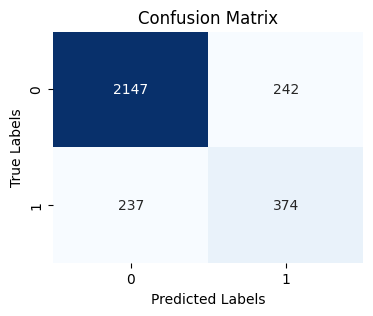

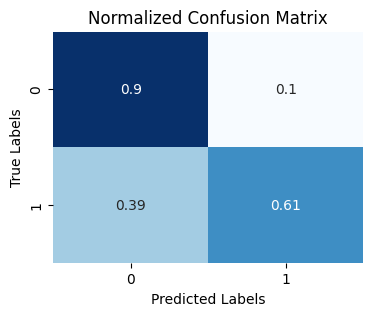

              precision    recall  f1-score   support

           0       0.90      0.90      0.90      2389
           1       0.61      0.61      0.61       611

    accuracy                           0.84      3000
   macro avg       0.75      0.76      0.75      3000
weighted avg       0.84      0.84      0.84      3000



In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

confusion_mat = confusion_matrix(y_test, predictions)
confusion_mat_normalized = np.around(confusion_mat / confusion_mat.sum(axis=1)[:, np.newaxis], 2)

# Visualizing the Confusion Matrix
plt.figure(figsize=(4, 3))
sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

plt.figure(figsize=(4, 3))
sns.heatmap(confusion_mat_normalized, annot=True, cmap='Blues', cbar=False)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix')
plt.show()
print(classification_report(y_test, predictions))

In [ ]:
predicted_label = rf_grid_search.predict(X_test[:1])
print(f"Predicted classes: {predicted_label}")
print(f"Actual Labels: {list(y_test[:1])}")

Predicted classes: [0]
Actual Labels: [1]
